# TASK 5 — Advanced Analysis (Telco Customer Churn)

**Prepared by: FEDELIKA MAXMUS**

## 1. Project / Task Objective

| Task-list requirement | How we do it in this notebook |
|-----------------------|-------------------------------|
| 1. Group customers by tenure → statistics for charges and churn | `groupby(tenure_group)` table: count, mean/median/std of charges, churn rate + lifecycle line chart |
| 2. Churn rates by demographics (gender, senior citizen), payment methods, contract types | `pd.crosstab(..., normalize='index')` tables + grouped bar charts with % annotations |
| 3. Trends over lifecycle stages to identify patterns | Churn-rate-vs-tenure curve, ARPU-vs-tenure curve, contract × tenure churn matrix |

**Goal (project overview):** turn Tasks 1–4 into *recommendations to reduce churn and improve retention*. Input is the Task-2 cleaned CSV.

## 2. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

## 3. Load Data + Tenure Groups

Same lifecycle buckets as Task 4 (0–12 / 13–36 / 37+ months) so Tasks 4–5 are directly comparable.

In [ ]:
try:
    df = pd.read_csv("Telco_Customer_Churn_Cleaned.csv")
except FileNotFoundError:
    df = pd.read_csv("Telco_Customer_Churn_Dataset  (3).csv")
    df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_", regex=False)
    df["totalcharges"] = pd.to_numeric(df["totalcharges"].astype(str).str.strip(), errors="coerce").fillna(0)
    df = df.drop_duplicates().reset_index(drop=True)

df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 36, 72],
                              labels=["0-12 months", "13-36 months", "37+ months"])
print(f"Loaded: {df.shape} | Nulls: {int(df.isnull().sum().sum())}")
print("Tenure groups:", df["tenure_group"].value_counts().to_dict())

Loaded: (7043, 22) | Nulls: 0
Tenure groups: {'37+ months': 3001, '0-12 months': 2186, '13-36 months': 1856}


## 4. Tenure-Group Statistics — charges + churn

**Method:** one `groupby` producing count, mean/median/std for `monthlycharges` and `totalcharges`, plus churn rate `(churn=='Yes').mean()`.

**Pattern to spot:** churn collapses as tenure grows (47.4% → 25.5% → 11.9%) while both monthly and lifetime value rise — the first-year cliff.

In [ ]:
stats = df.groupby("tenure_group", observed=True).agg(
    n=("churn", "size"),
    avg_monthly=("monthlycharges", "mean"),
    median_monthly=("monthlycharges", "median"),
    avg_total=("totalcharges", "mean"),
    median_total=("totalcharges", "median"),
    churn_rate=("churn", lambda s: (s == "Yes").mean() * 100))
print(stats.round(2).to_string())
print("\nReading: churn nearly halves each lifecycle step while avg monthly rises 56.10 -> 72.01. Retention priority = survive year one.")

                 n  avg_monthly  median_monthly  avg_total  median_total  churn_rate
tenure_group                                                                        
0-12 months   2186        56.10           55.90     275.23        170.88       47.44
13-36 months  1856        63.25           69.68    1513.54       1404.98       25.54
37+ months    3001        72.01           80.30    4213.72       4282.40       11.93

Reading: churn nearly halves each lifecycle step while avg monthly rises 56.10 -> 72.01. Retention priority = survive year one.


## 5. Churn by Demographics — gender & senior-citizen status

**Method:** row-normalised crosstabs (each row = 100%) so groups of different size are comparable.

**Result:** gender is essentially neutral (Female 26.9% vs Male 26.2%, gap 0.8 pts — not actionable). Senior-citizen status is a real flag: seniors churn at **41.7%** vs **23.6%** for non-seniors (+18 pts).

--- Churn % by gender ---
churn      No    Yes
gender              
Female  73.08  26.92
Male    73.84  26.16

--- Churn % by seniorcitizen ---
churn             No    Yes
seniorcitizen              
0              76.39  23.61
1              58.32  41.68



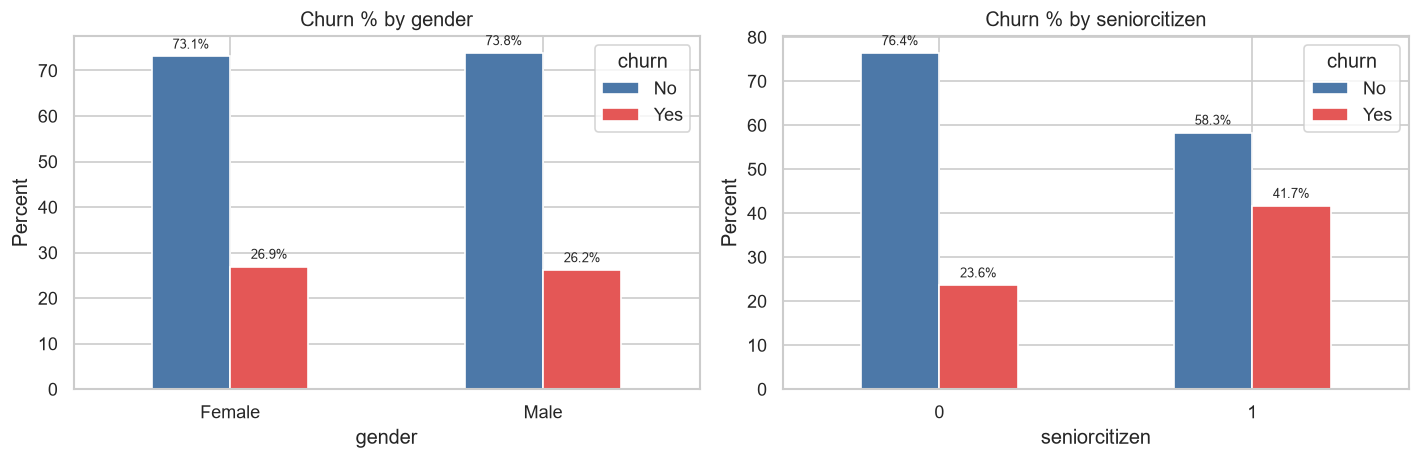

In [ ]:
for col in ["gender", "seniorcitizen"]:
    ct = (pd.crosstab(df[col], df["churn"], normalize="index") * 100).round(2)
    print(f"--- Churn % by {col} ---")
    print(ct.to_string())
    print()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["gender", "seniorcitizen"]):
    ct = (pd.crosstab(df[col], df["churn"], normalize="index") * 100).round(2)
    ct.plot(kind="bar", stacked=False, ax=ax, color=["#4C78A8", "#E45756"])
    ax.set_title(f"Churn % by {col}")
    ax.set_ylabel("Percent")
    ax.tick_params(axis="x", rotation=0)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.1f%%", padding=3, fontsize=8)
plt.tight_layout()
plt.show()

## 6. Churn by Contract & Payment Method (business levers)

**Strongest signals in the whole project:**
- Contract: `Month-to-month` **42.7%** vs `One year` 11.3% vs `Two year` **2.8%** — commitment is the #1 churn shield.
- Payment: `Electronic check` **45.3%** vs auto-pay (`Credit card` 15.2%, `Bank transfer` 16.7%) and `Mailed check` 19.1% — manual e-check is the friction flag.

--- Churn % by contract ---
churn              No    Yes
contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83

--- Churn % by paymentmethod ---
churn                         No    Yes
paymentmethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11



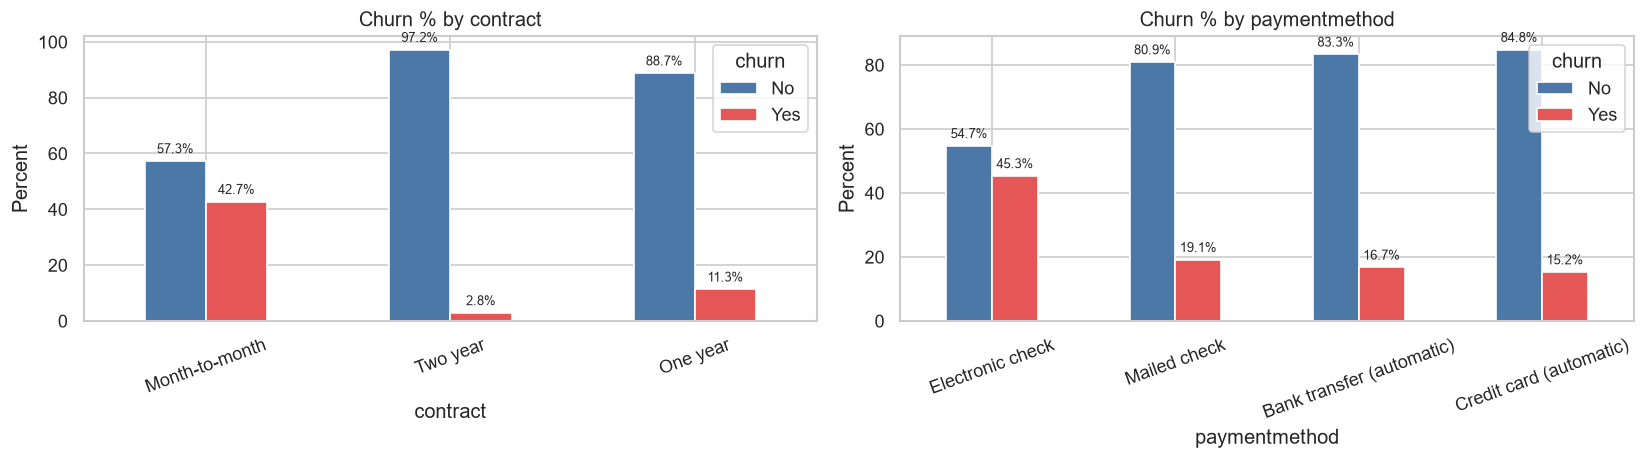

In [ ]:
for col in ["contract", "paymentmethod"]:
    ct = (pd.crosstab(df[col], df["churn"], normalize="index") * 100).round(2)
    print(f"--- Churn % by {col} ---")
    print(ct.to_string())
    print()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ["contract", "paymentmethod"]):
    order = df[col].value_counts().index
    ct = (pd.crosstab(df[col], df["churn"], normalize="index") * 100).round(2).reindex(order)
    ct.plot(kind="bar", ax=ax, color=["#4C78A8", "#E45756"])
    ax.set_title(f"Churn % by {col}")
    ax.set_ylabel("Percent")
    ax.tick_params(axis="x", rotation=20)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.1f%%", padding=3, fontsize=8)
plt.tight_layout()
plt.show()

## 7. Lifecycle Trends — churn falls as value rises

Two curves on twin axes across `0–12 → 13–36 → 37+` months: churn rate (red, falling 47.4 → 11.9) vs avg monthly charges (blue, rising 56.1 → 72.0). The crossing visual is the executive story: **the customers most likely to leave are the cheapest — saving them early unlocks the high-value loyal stage.**

The contract × tenure matrix below it shows the lever works at every stage: month-to-month churn (51.4% → 35.7% → 29.6%) always dwarfs 1–2 year contracts.

              churn_rate  avg_monthly
tenure_group                         
0-12 months        47.44        56.10
13-36 months       25.54        63.25
37+ months         11.93        72.01


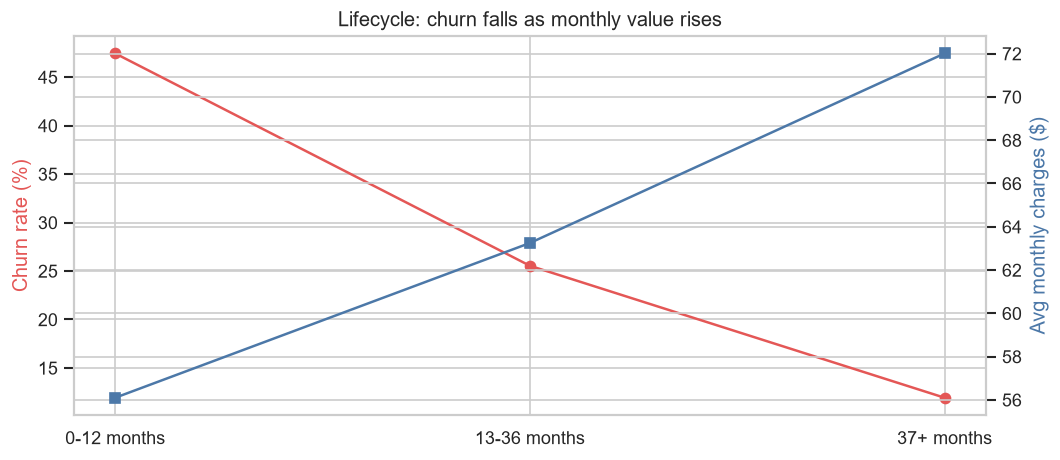

tenure_group    0-12 months  13-36 months  37+ months
contract                                             
Month-to-month        51.35         35.65       29.64
One year              10.48          8.05       12.97
Two year               0.00          1.08        3.19


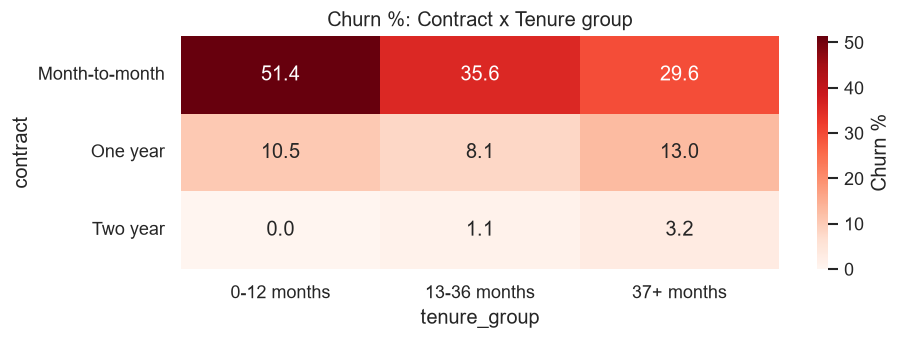

In [ ]:
trend = df.groupby("tenure_group", observed=True).agg(
    churn_rate=("churn", lambda s: (s == "Yes").mean() * 100),
    avg_monthly=("monthlycharges", "mean")).reindex(["0-12 months", "13-36 months", "37+ months"])
print(trend.round(2).to_string())

fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(trend.index, trend["churn_rate"], marker="o", color="#E45756", label="Churn rate %")
ax1.set_ylabel("Churn rate (%)", color="#E45756")
ax2 = ax1.twinx()
ax2.plot(trend.index, trend["avg_monthly"], marker="s", color="#4C78A8", label="Avg monthly ($)")
ax2.set_ylabel("Avg monthly charges ($)", color="#4C78A8")
plt.title("Lifecycle: churn falls as monthly value rises")
fig.tight_layout()
plt.show()

matrix = df.groupby(["contract", "tenure_group"], observed=True)["churn"].apply(lambda s: (s == "Yes").mean() * 100).round(2).unstack("tenure_group")
print(matrix.to_string())

plt.figure(figsize=(8, 3))
sns.heatmap(matrix, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Churn %"})
plt.title("Churn %: Contract x Tenure group")
plt.tight_layout()
plt.show()

## 8. Findings / Conclusion + Recommendations

**Tenure grouping:** 0–12 mo (n=2186): churn **47.4%**, avg monthly **56.10**, avg total 275.2 · 13–36 mo (n=1856): 25.5%, 63.25, 1513.5 · 37+ mo (n=3001): **11.9%**, 72.01, 4213.7.

**Demographics:** gender neutral (F 26.9% vs M 26.2%) — do not target by gender. Senior citizens **41.7% vs 23.6%** — priority support/onboarding segment.

**Commercial levers:** Month-to-month **42.7%** vs Two-year **2.8%** (15× gap); Electronic check **45.3%** vs auto-pay ~15–17%. Contract × tenure matrix: month-to-month is worst at every lifecycle stage (0–12: 51.4%, 37+: still 29.6%).

**Lifecycle pattern:** churn halves each stage while ARPU rises — the first year is the cliff; survivors become the highest-value customers.